# Mobile Classification 실습

## 데이터 불러오기

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

tf.keras.utils.set_random_seed(42)   # 결과 재현용 시드 고정

df = pd.read_csv('mobile.csv')
print(df.shape)                  # (2000, 21): 2000행, 특성 20 + 타깃 1
df.head()

(2000, 21)


,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
0,842,0,2.2,0,1,0,7,0.6,188,2,...,20,756,2549,9,7,19,0,0,1,1
1,1021,1,0.5,1,0,1,53,0.7,136,3,...,905,1988,2631,17,3,7,1,1,0,2
2,563,1,0.5,1,2,1,41,0.9,145,5,...,1263,1716,2603,11,2,9,1,1,0,2
3,615,1,2.5,0,0,0,10,0.8,131,6,...,1216,1786,2769,16,8,11,1,0,0,2
4,1821,1,1.2,0,13,1,44,0.6,141,2,...,1208,1212,1411,8,2,15,1,1,0,1


## 1. 결측치 확인

In [ ]:
df.isnull().sum()   # 컬럼별 NaN 개수 → 전부 0


,0
battery_power,0
blue,0
clock_speed,0
dual_sim,0
fc,0
four_g,0
int_memory,0
m_dep,0
mobile_wt,0
n_cores,0


In [ ]:
# NaN은 없지만 0이 들어갈 수 없는 컬럼에 0이 있으면 사실상 결측치
zero_cnt = (df == 0).sum()
zero_cnt[zero_cnt > 0]   # 이진 컬럼(blue, wifi 등)과 fc, pc의 0은 정상값(없음/미탑재)

,0
blue,1010
dual_sim,981
fc,474
four_g,957
pc,101
px_height,2
sc_w,180
three_g,477
touch_screen,994
wifi,986


In [ ]:
# 화면 너비(sc_w)와 세로 해상도(px_height)가 0인 건 물리적으로 불가능 → 결측치로 판단
print('sc_w = 0      :', (df['sc_w'] == 0).sum(), '행')        # 180행
print('px_height = 0 :', (df['px_height'] == 0).sum(), '행')   # 2행

df[['sc_w', 'px_height']] = df[['sc_w', 'px_height']].replace(0, np.nan)   # 0 → NaN으로 표시
df.isnull().sum()[['sc_w', 'px_height']]   # 분할 후 train 중앙값으로 채움(4번 단계)


sc_w = 0      : 180 행
px_height = 0 : 2 행


,0
sc_w,180
px_height,2


## 2. 라벨 분포 확인

In [ ]:
print(df['price_range'].value_counts().sort_index())                # 클래스별 개수 → 각 500개
print(df['price_range'].value_counts(normalize=True).sort_index())   # 비율 → 각 25%, 완전 균형

price_range
0    500
1    500
2    500
3    500
Name: count, dtype: int64
price_range
0    0.25
1    0.25
2    0.25
3    0.25
Name: proportion, dtype: float64


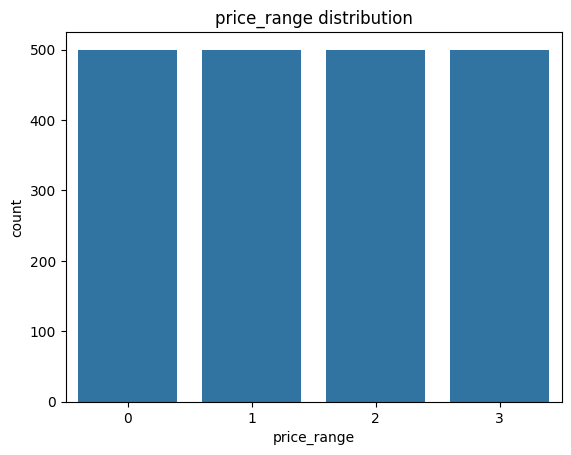

In [ ]:
sns.countplot(data=df, x='price_range')   # 균형 데이터 → accuracy를 평가 지표로 써도 무방
plt.title('price_range distribution')
plt.show()

## 3. EDA

In [ ]:
df.describe().T.round(2)   # 특성별 범위 차이 큼(ram 수천, m_dep 1 이하) → 스케일링 필요

,count,mean,std,min,25%,50%,75%,max
battery_power,2000.0,1238.52,439.42,501.0,851.75,1226.0,1615.25,1998.0
blue,2000.0,0.50,0.50,0.0,0.00,0.0,1.00,1.0
clock_speed,2000.0,1.52,0.82,0.5,0.70,1.5,2.20,3.0
dual_sim,2000.0,0.51,0.50,0.0,0.00,1.0,1.00,1.0
fc,2000.0,4.31,4.34,0.0,1.00,3.0,7.00,19.0
four_g,2000.0,0.52,0.50,0.0,0.00,1.0,1.00,1.0
int_memory,2000.0,32.05,18.15,2.0,16.00,32.0,48.00,64.0
m_dep,2000.0,0.50,0.29,0.1,0.20,0.5,0.80,1.0
mobile_wt,2000.0,140.25,35.40,80.0,109.00,141.0,170.00,200.0
n_cores,2000.0,4.52,2.29,1.0,3.00,4.0,7.00,8.0


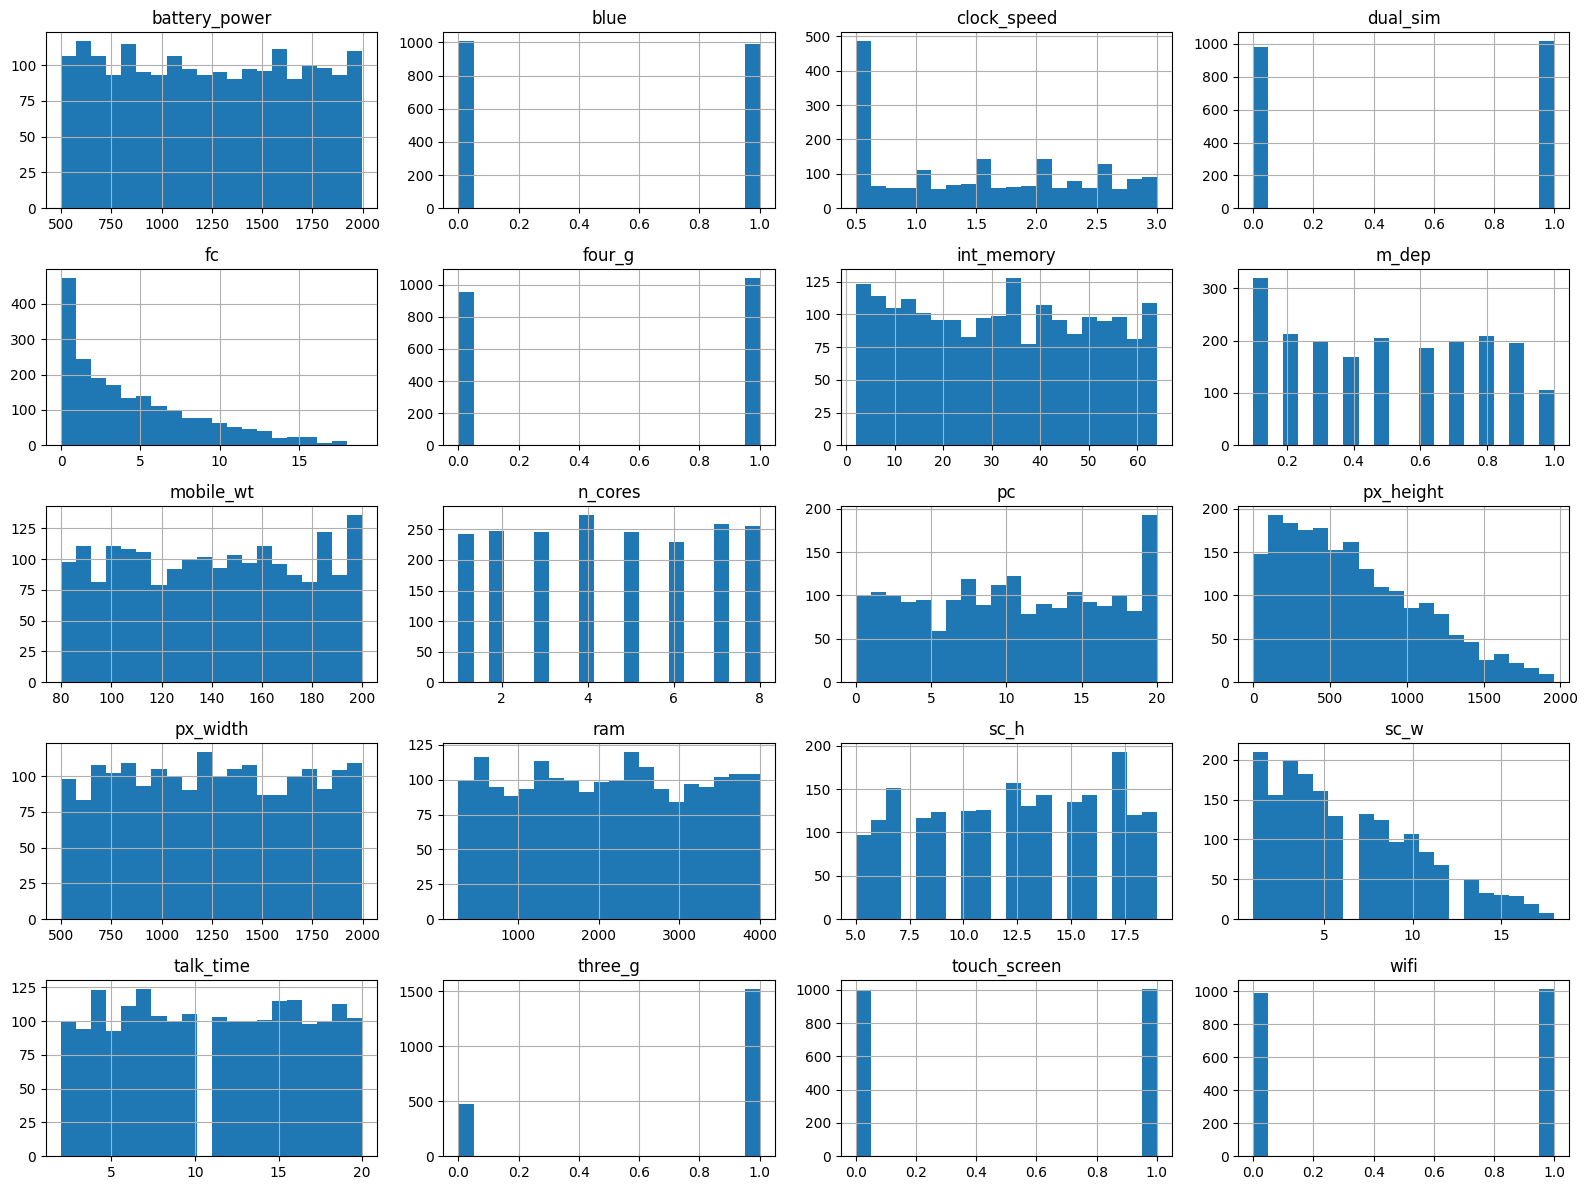

In [ ]:
df.drop(columns='price_range').hist(figsize=(16, 12), bins=20)   # 특성별 분포
plt.tight_layout()                                               # 대부분 균등분포, fc만 오른쪽 꼬리
plt.show()

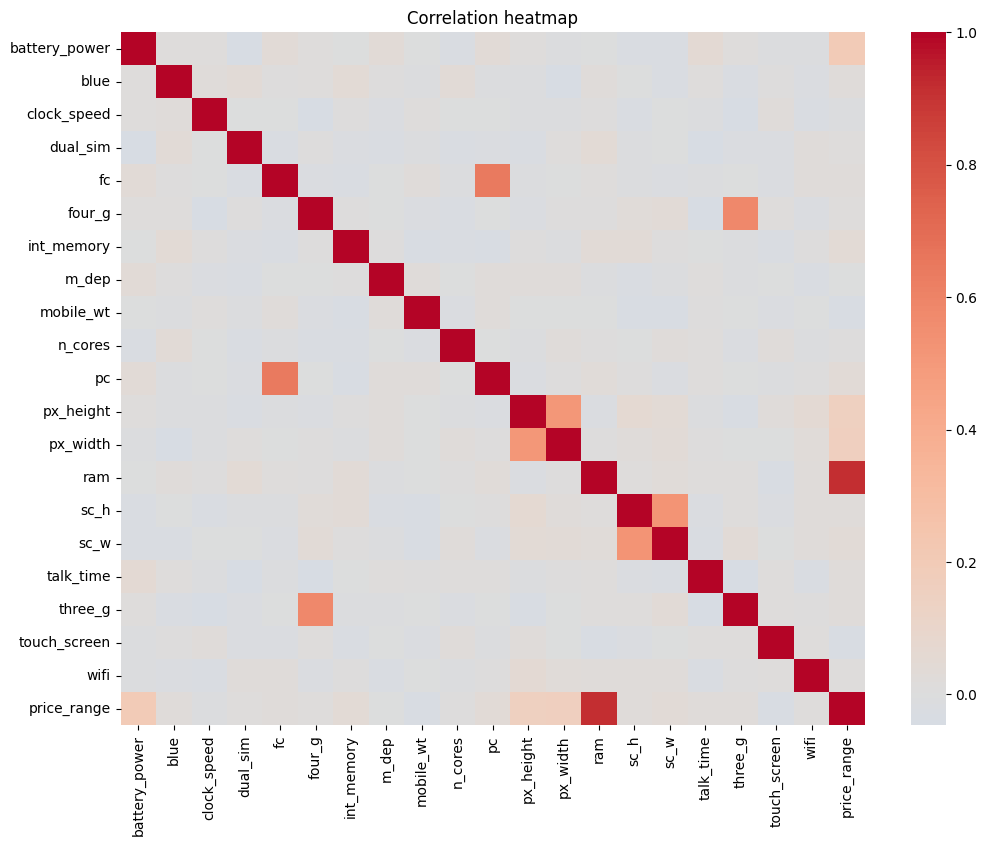

In [ ]:
plt.figure(figsize=(12, 9))
sns.heatmap(df.corr(), cmap='coolwarm', center=0)   # 특성 간 최대 상관 fc-pc 0.64, three_g-four_g 0.58
plt.title('Correlation heatmap')                    # 0.7 미만으로 강한 다중공선성은 아님 → 특성 제거 안 함
plt.show()

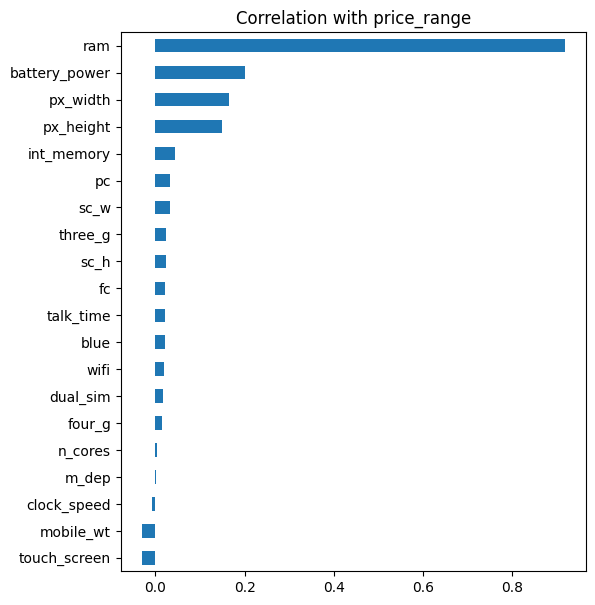

In [ ]:
corr = df.corr()['price_range'].drop('price_range').sort_values()   # 타깃과의 상관계수
corr.plot.barh(figsize=(6, 7))                                       # ram 0.92로 압도적, 나머지는 거의 0
plt.title('Correlation with price_range')
plt.show()

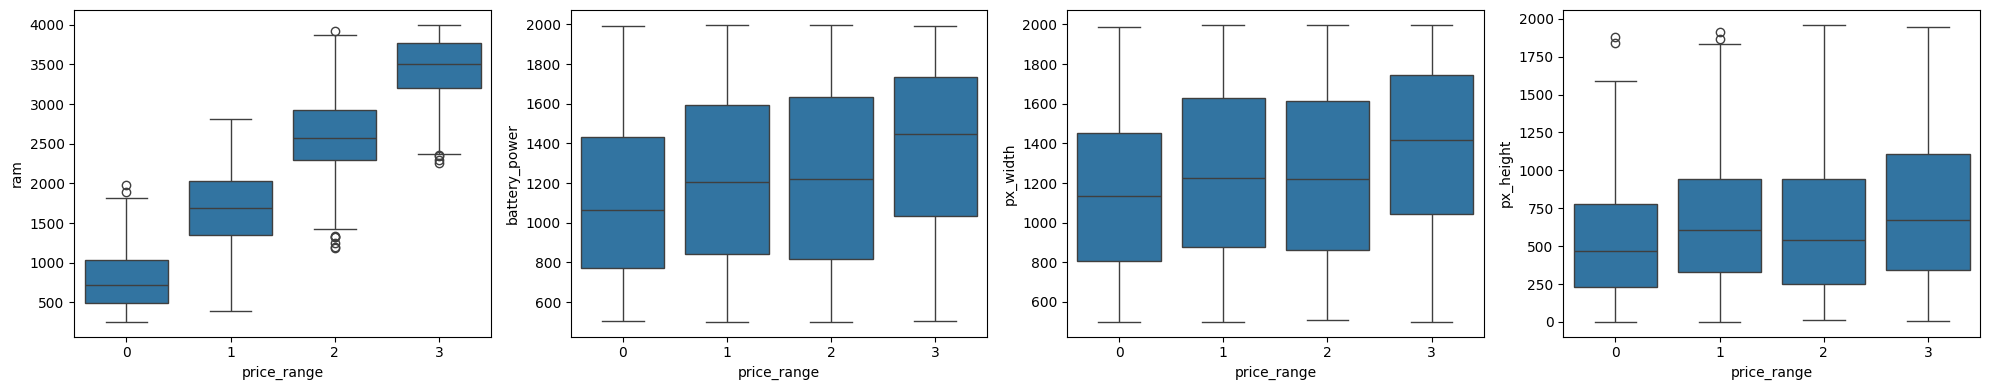

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, col in zip(axes, ['ram', 'battery_power', 'px_width', 'px_height']):   # 상관 상위 4개
    sns.boxplot(data=df, x='price_range', y=col, ax=ax)                        # ram은 가격대별로 뚜렷이 구분
plt.tight_layout()
plt.show()

## 4. 데이터 분할 · 결측치 처리 · 스케일링

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.utils import to_categorical

X = df.drop(columns='price_range')   # 입력: 사양 20개
y = df['price_range']                # 타깃: 가격대 0~3

# train 60% / validation 20% / test 20%
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)        # test는 마지막 최종 평가에만 사용
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.25, random_state=42, stratify=y_temp)   # 모델 비교·원인 분석은 validation으로

medians = X_train[['sc_w', 'px_height']].median()   # train 기준 중앙값 (val/test 정보 누출 방지)
X_train, X_val, X_test = X_train.fillna(medians), X_val.fillna(medians), X_test.fillna(medians)
print('남은 결측치:', X_train.isnull().sum().sum(), X_val.isnull().sum().sum(), X_test.isnull().sum().sum())

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)   # train으로만 평균/표준편차 학습
X_val_s   = scaler.transform(X_val)         # val/test는 변환만
X_test_s  = scaler.transform(X_test)

y_train_oh = to_categorical(y_train, 4)   # DNN용 원-핫 라벨 (예: 2 → [0,0,1,0])
y_val_oh   = to_categorical(y_val, 4)
y_test_oh  = to_categorical(y_test, 4)

print(X_train.shape, X_val.shape, X_test.shape)                  # (1200, 20) (400, 20) (400, 20)
print('train:', y_train.value_counts().sort_index().to_dict())   # 각 300개
print('val  :', y_val.value_counts().sort_index().to_dict())     # 각 100개
print('test :', y_test.value_counts().sort_index().to_dict())    # 각 100개
print(y_train_oh[:3])                                            # 원-핫 변환 확인

남은 결측치: 0 0 0
(1200, 20) (400, 20) (400, 20)
train: {0: 300, 1: 300, 2: 300, 3: 300}
val  : {0: 100, 1: 100, 2: 100, 3: 100}
test : {0: 100, 1: 100, 2: 100, 3: 100}
[[0. 0. 0. 1.]
 [0. 0. 0. 1.]
 [0. 0. 1. 0.]]


## 5. 딥러닝(DNN) 모델 — loss · metric · activation

In [ ]:
from tensorflow import keras
from tensorflow.keras import layers

def build_model(hidden=(64, 32), last_activation='softmax'):
    model = keras.Sequential([layers.Input(shape=(20,))])          # 입력: 특성 20개
    for units in hidden:
        model.add(layers.Dense(units, activation='relu'))          # 은닉층
    model.add(layers.Dense(4, activation=last_activation))         # 출력층: 클래스 4개, softmax → 확률 합 1
    model.compile(
        optimizer='adam',
        loss='categorical_crossentropy',
        metrics=['accuracy'],              # 균형 데이터라 정확도로 평가
    )
    return model

def train_eval(model, Xtr, Xv, epochs=300):
    early_stop = keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=10,    # val loss가 10 epoch 동안 안 줄면 중단
        restore_best_weights=True)          # 가장 좋았던 시점의 가중치로 복원 → 과적합 방지
    hist = model.fit(Xtr, y_train_oh, validation_data=(Xv, y_val_oh),   # 원-핫 라벨 사용
                     epochs=epochs, batch_size=32, callbacks=[early_stop], verbose=0)
    val_acc = model.evaluate(Xv, y_val_oh, verbose=0)[1]   # validation 정확도 반환
    return hist, val_acc

dnn = build_model()
dnn.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_10 (Dense)                │ (None, 64)             │         1,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,556 (13.89 KB)

 Trainable params: 3,556 (13.89 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history, dnn_val_acc = train_eval(dnn, X_train_s, X_val_s)
print('학습 epoch 수:', len(history.history['loss']))
print('DNN val accuracy:', round(dnn_val_acc, 3))

학습 epoch 수: 38
DNN val accuracy: 0.9


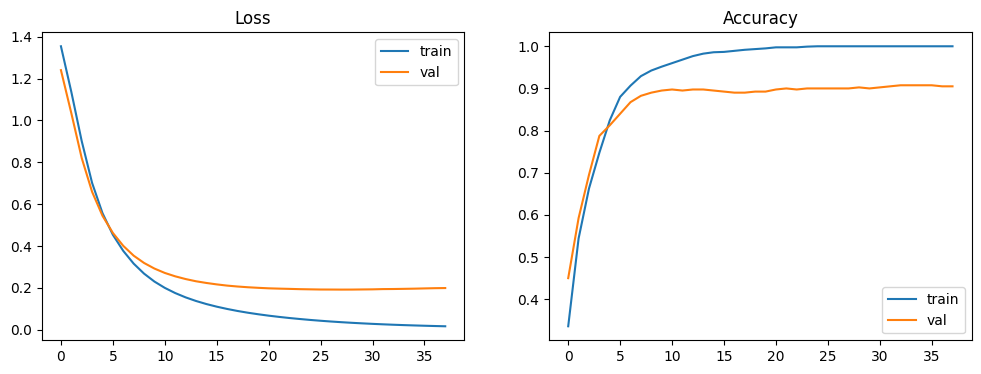

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history.history['loss'], label='train')
axes[0].plot(history.history['val_loss'], label='val')           # val loss가 다시 오르기 직전에 학습 중단
axes[0].set_title('Loss'); axes[0].legend()
axes[1].plot(history.history['accuracy'], label='train')
axes[1].plot(history.history['val_accuracy'], label='val')
axes[1].set_title('Accuracy'); axes[1].legend()
plt.show()

In [ ]:
probs = dnn.predict(X_val_s, verbose=0)   # softmax 출력: 샘플별 4개 클래스 확률
print(probs[:3].round(3))                 # 각 행의 합 = 1
print(probs[:3].sum(axis=1))              # argmax(가장 큰 확률)가 예측 클래스

[[0.    0.557 0.443 0.   ]
 [0.    0.005 0.99  0.004]
 [0.    0.996 0.003 0.   ]]
[0.99999994 1.         1.        ]


## 6. 머신러닝 모델과 비교 (validation)

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

models = {
    'Logistic Regression': LogisticRegression(max_iter=2000),          # 선형 기준선 (DNN과 비교용)
    'KNN':                 KNeighborsClassifier(),                     # 거리 기반 → 원인 분석 ①에서 사용
    'Random Forest':       RandomForestClassifier(random_state=42),    # 특성 중요도 확인용
}

results = [{'model': 'DNN (은닉층 2개)', 'val_acc': dnn_val_acc}]
for name, m in models.items():
    m.fit(X_train_s, y_train)
    results.append({'model': name, 'val_acc': accuracy_score(y_val, m.predict(X_val_s))})

result_df = pd.DataFrame(results).sort_values('val_acc', ascending=False).round(3)
result_df   # KNN만 유독 낮고, DNN이 로지스틱보다 낮음 → 7번에서 원인 분석

,model,val_acc
1,Logistic Regression,0.968
0,DNN (은닉층 2개),0.900
3,Random Forest,0.842
2,KNN,0.507


## 7. 성능이 낮은 경우 원인 분석 (validation)

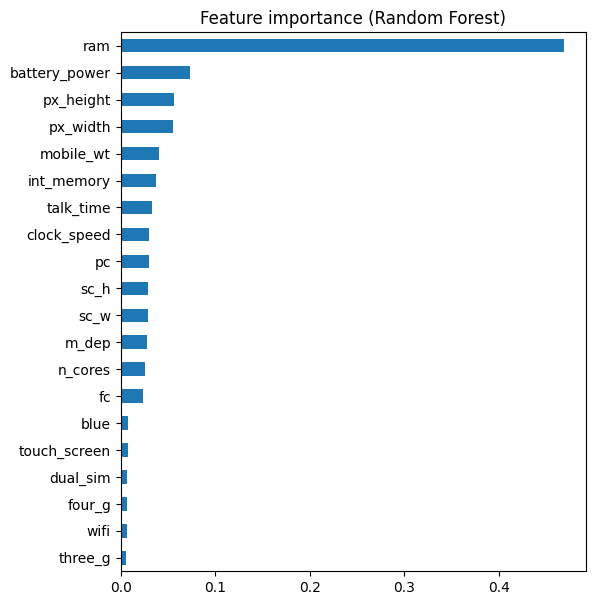

In [ ]:
# [원인 1] KNN: 무관한 특성이 거리 계산을 방해
rf = models['Random Forest']
importance = pd.Series(rf.feature_importances_, index=X.columns).sort_values()
importance.plot.barh(figsize=(6, 7))   # 중요한 특성은 ram 등 소수뿐
plt.title('Feature importance (Random Forest)')
plt.show()

In [ ]:
top4 = ['ram', 'battery_power', 'px_width', 'px_height']   # 중요도 상위 4개
idx = [X.columns.get_loc(c) for c in top4]

knn = KNeighborsClassifier()
knn.fit(X_train_s, y_train)
print('KNN 전체 20개:', round(accuracy_score(y_val, knn.predict(X_val_s)), 3))            # 낮음

knn.fit(X_train_s[:, idx], y_train)
print('KNN 상위 4개 :', round(accuracy_score(y_val, knn.predict(X_val_s[:, idx])), 3))    # 크게 상승 → 원인 확인

KNN 전체 20개: 0.507
KNN 상위 4개 : 0.892


In [ ]:
# [원인 2] 스케일링 누락: 값이 큰 특성(ram 등)이 학습을 지배
tf.keras.utils.set_random_seed(42)
_, raw_acc = train_eval(build_model(), X_train.values, X_val.values)   # 스케일링 안 한 원본 입력
print('DNN 스케일링 X:', round(raw_acc, 3))       # 성능 하락
print('DNN 스케일링 O:', round(dnn_val_acc, 3))

DNN 스케일링 X: 0.673
DNN 스케일링 O: 0.9


In [ ]:
# [원인 3] 출력층 activation: softmax의 필요성을 확인하기 위한 대조 실험
# relu는 음수를 0으로 잘라 출력이 확률 분포가 되지 않음
tf.keras.utils.set_random_seed(42)
_, relu_acc = train_eval(build_model(last_activation='relu'), X_train_s, X_val_s)
print('출력층 relu   :', round(relu_acc, 3))      # 학습 실패
print('출력층 softmax:', round(dnn_val_acc, 3))

출력층 relu   : 0.25
출력층 softmax: 0.9


In [ ]:
# [원인 4] 모델이 데이터에 비해 너무 복잡: 경계가 거의 선형인데 은닉층이 과적합 유발
tf.keras.utils.set_random_seed(42)
simple = build_model(hidden=())                   # 은닉층 없음 = 로지스틱 회귀와 같은 구조
_, simple_acc = train_eval(simple, X_train_s, X_val_s, epochs=1000)
print('은닉층 2개 DNN:', round(dnn_val_acc, 3))
print('은닉층 없는 DNN:', round(simple_acc, 3))   # 더 단순한 모델이 더 높음

은닉층 2개 DNN: 0.9
은닉층 없는 DNN: 0.975


## 8. 최종 평가 (test)

In [ ]:
# validation 결과로 최종 모델 선택 → test는 여기서 한 번만 사용
final_model = simple   # 은닉층 없는 DNN (validation 기준 DNN 중 최고)
test_loss, test_acc = final_model.evaluate(X_test_s, y_test_oh, verbose=0)   # 원-핫 라벨로 평가
print(f'최종 모델 test loss: {test_loss:.3f}, test accuracy: {test_acc:.3f}')

최종 모델 test loss: 0.144, test accuracy: 0.967


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

test_pred = final_model.predict(X_test_s, verbose=0).argmax(axis=1)   # 확률 → 클래스
print(classification_report(y_test, test_pred))                      # 클래스별 precision / recall / f1

              precision    recall  f1-score   support

           0       0.98      0.99      0.99       100
           1       0.98      0.95      0.96       100
           2       0.94      0.96      0.95       100
           3       0.97      0.97      0.97       100

    accuracy                           0.97       400
   macro avg       0.97      0.97      0.97       400
weighted avg       0.97      0.97      0.97       400



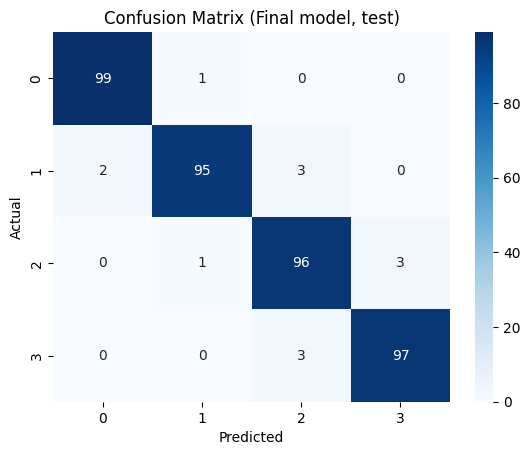

In [ ]:
cm = confusion_matrix(y_test, test_pred)             # 행: 실제, 열: 예측
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')   # 오답은 대각선 바로 옆(인접 가격대)에 몰림
plt.xlabel('Predicted'); plt.ylabel('Actual')
plt.title('Confusion Matrix (Final model, test)')
plt.show()

## 9. 결과 정리

**평가 방식**
- 데이터를 train 60% / validation 20% / test 20%로 나눴다.
- 모델 비교와 원인 분석은 모두 validation으로 했고, test는 최종 선택한 모델을 평가할 때 **한 번만** 사용했다.

**모델별 Validation 정확도**

| 모델 | Val 정확도 |
|---|---|
| DNN (은닉층 없음) | **0.975** |
| Logistic Regression | 0.968 |
| DNN (은닉층 2개) | 0.900 |
| Random Forest | 0.842 |
| KNN | 0.507 |

**5. 성능이 낮은 경우 원인 분석 (validation 기준)**

| 원인 | 실험 | 결과 |
|---|---|---|
| ① 무관한 특성이 거리 계산 방해 (KNN) | 특성 20개 → 상위 4개 | 0.507 → **0.892** |
| ② 스케일링 누락 | DNN 스케일링 X vs O | 0.695 → **0.900** |
| ③ 출력층 activation (대조 실험) | 출력층 relu vs softmax | 0.255 → **0.900** |
| ④ 모델이 데이터에 비해 과하게 복잡 | DNN 은닉층 2개 vs 없음 | 0.900 → **0.975** |

- ① KNN은 모든 특성을 같은 비중으로 거리에 반영한다. 가격과 무관한 특성 16개가 ram의 차이를 묻어버려 0.51에 그쳤고, 중요한 특성 4개만 남기자 0.89로 올랐다.
- ② 스케일링을 안 하면 ram처럼 값이 큰 특성이 가중치 업데이트를 지배해 학습이 제대로 되지 않았다.
- ③ 출력층에 relu를 쓰면 음수가 0으로 잘려 출력이 확률 분포가 되지 않는다. 정확도 0.25는 4개 중 무작위로 고르는 수준이며, 다중 분류 출력층에 softmax가 필요함을 확인했다.
- ④ 이 데이터는 가격대 경계가 거의 선형이다. 은닉층이 있는 DNN은 1,200개 학습 데이터에 비해 표현력이 과해 과적합되었고, 은닉층 없는 모델(로지스틱 회귀와 같은 구조)이 더 높았다.

**최종 결과 (test)**
- validation에서 가장 높았던 **은닉층 없는 DNN**을 최종 모델로 선택했다.
- test 정확도 **0.967**, test loss 0.144로 validation(0.975)과 비슷해 일반화가 잘 되었다.
- 오분류는 대부분 인접 가격대(1↔2 등) 사이에서 발생했다.

**느낀 점**
- 복잡한 모델이 항상 좋은 것은 아니고, EDA로 데이터 구조를 먼저 파악한 뒤 그에 맞는 모델을 고르는 것이 중요하다는 것을 확인했다.
- 결측치 확인, 스케일링, 출력층·loss 설정 같은 기본 설정 하나가 성능을 크게 좌우했다.
- 성능이 낮을 때 원인을 추측만 하지 않고, 조건을 하나씩 바꾸는 실험으로 직접 확인할 수 있었다.
- validation과 test를 분리해, test를 모델 선택에 쓰지 않고 최종 성능 확인에만 쓰는 것이 공정한 평가라는 점을 배웠다.